# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import BHPoolsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 180


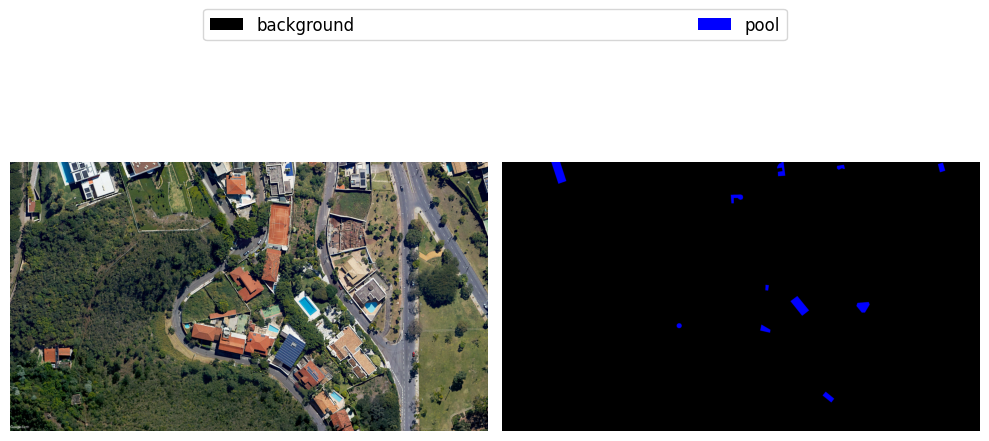

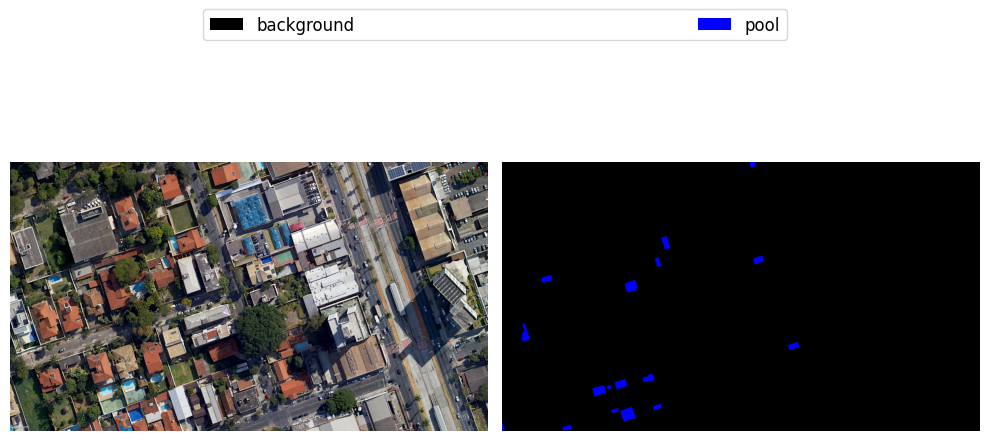

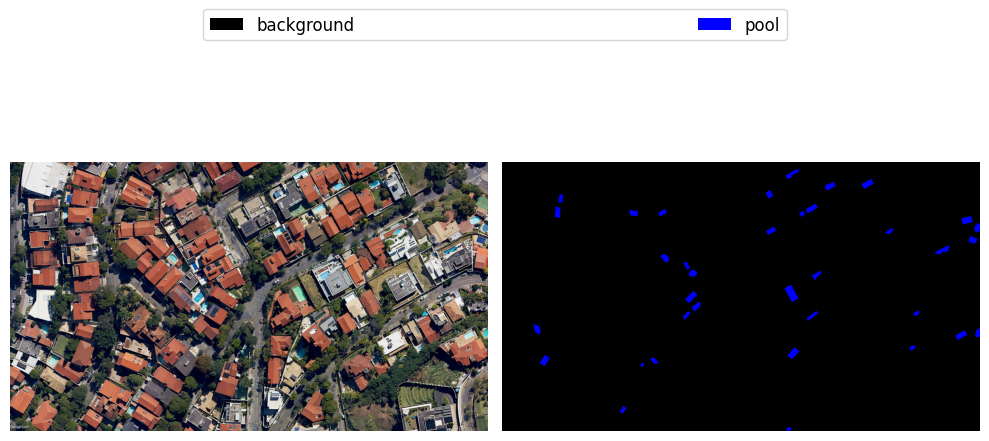

In [ ]:
dataset_config = {
    "data_dir": "./data/BH-Pools/train"
}
dataset = BHPoolsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(50);
dataset.show_image(170);

In [5]:
dataset.data_distribution_table()

,Number of pixels
background,1.480575e+09
pool,1.241705e+07


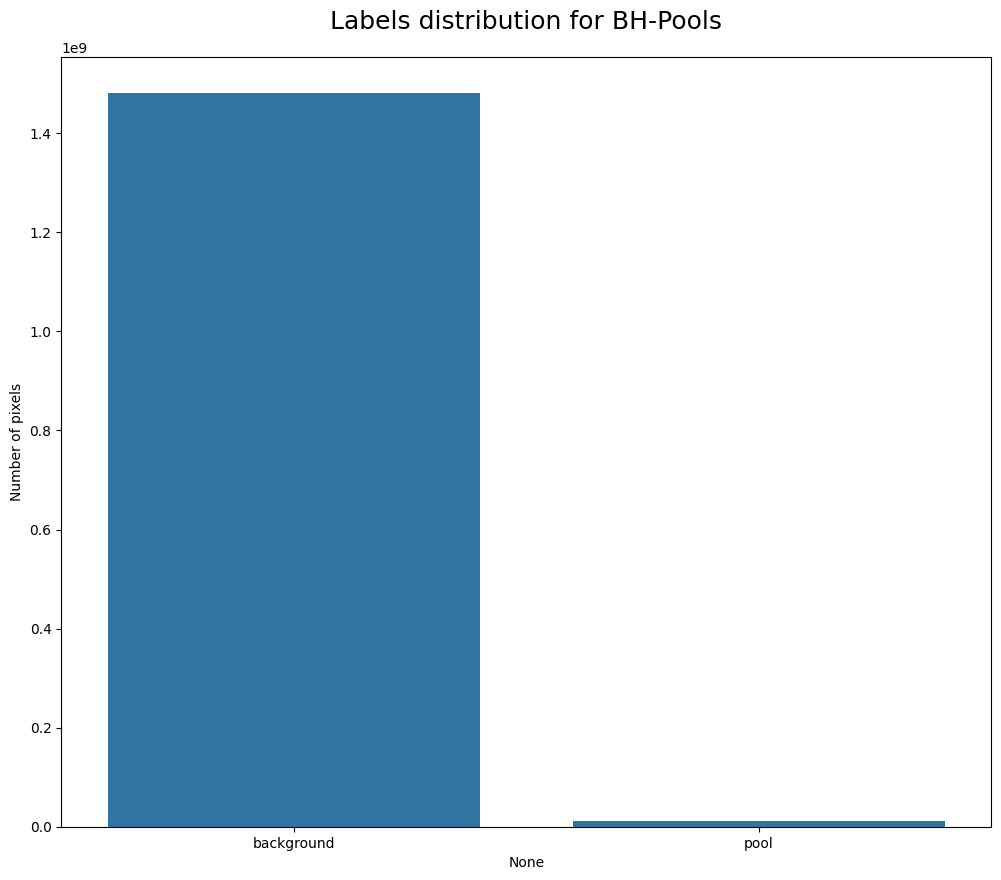

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/BH-Pools/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = BHPoolsDataset(train_dataset_config)
len(train_dataset)

180

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/BH-Pools"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-06 07:50:19,912 INFO Starting training.
training: 100%|██████████| 18/18 [18:48<00:00, 62.69s/it]  
2025-03-06 08:09:08,431 INFO epoch: 1, time: 1128, loss:  0.48007
testing on train set: 100%|██████████| 18/18 [18:46<00:00, 62.60s/it]  
2025-03-06 08:27:57,167 INFO IOU:0.2161683167816487, IOU mean:0.16181604851273196, IOU per Class:[0.32058628 0.00304581]
training: 100%|██████████| 18/18 [18:54<00:00, 63.02s/it]  
2025-03-06 08:46:51,536 INFO epoch: 2, time: 1134, loss:  0.40532
testing on train set: 100%|██████████| 18/18 [18:56<00:00, 63.14s/it]  
2025-03-06 09:05:48,021 INFO IOU:0.45144611792682693, IOU mean:0.31327878096823064, IOU per Class:[0.62408764 0.00246992]
training: 100%|██████████| 18/18 [18:53<00:00, 62.99s/it]  
2025-03-06 09:24:41,919 INFO epoch: 3, time: 1133, loss:  0.36525
testing on train set: 100%|██████████| 18/18 [18:47<00:00, 62.66s/it]  
2025-03-06 09:43:29,733 INFO IOU:0.766681179675874, IOU mean:0.4707747267842357, IOU per Class:[0.93899153 0.002557

## Predictions

2025-03-10 09:31:52,773 INFO Loading checkpoint /home/dragik/data/FAIR_EO/BH-Pools/checkpoint.pth.tar
2025-03-10 09:31:53,266 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/BH-Pools/checkpoint.pth.tar at epoch 11


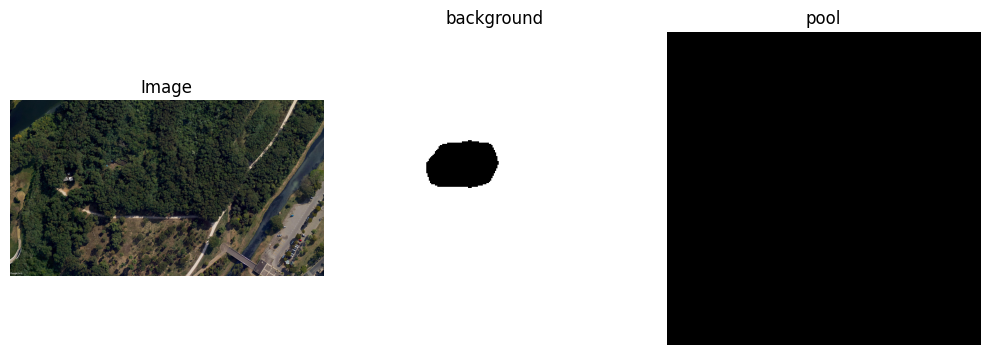

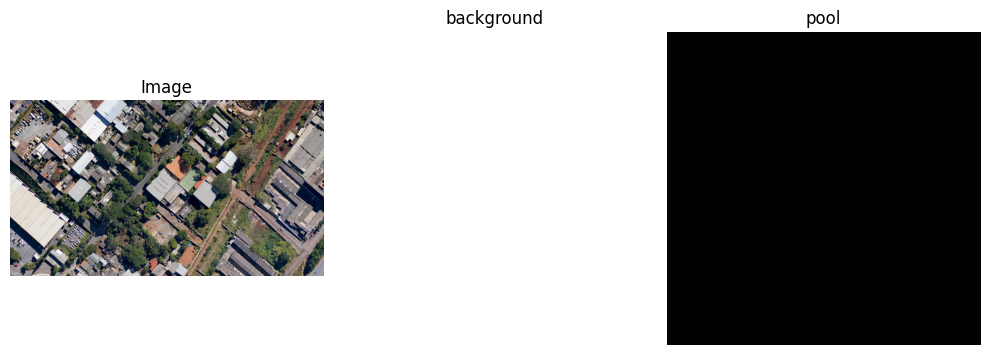

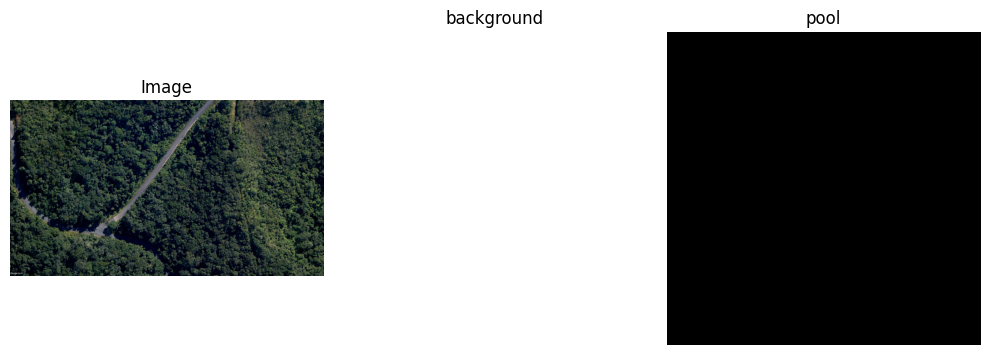

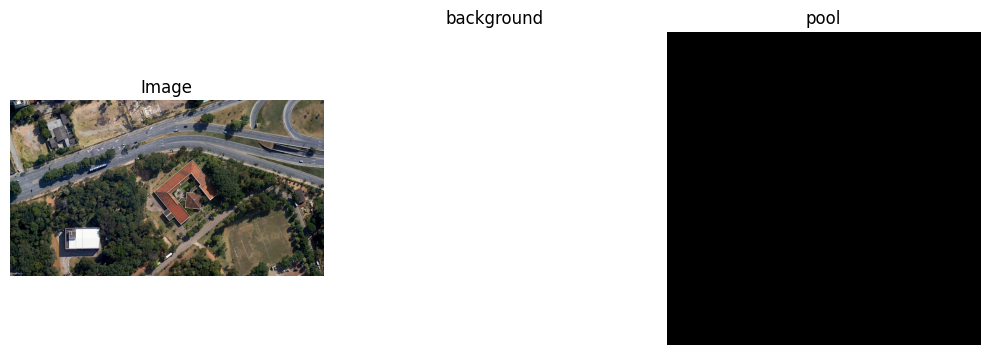

In [ ]:
model_path = "./data/BH-Pools/checkpoint.pth.tar"
labels = ["background","pool"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/BH-Pools/test/images/REGION_1_1.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BH-Pools/test/images/REGION_2_1.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BH-Pools/test/images/REGION_2_20.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BH-Pools/test/images/REGION_5_25.jpg')
fig = model.predict_masks(image, labels, transform)